## Exploratory Data Analysis

In [1]:
import sys
sys.path.append("..")   # make src/ importable from notebooks/
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_raw, load_clean

## Data Overview

In [2]:
df = load_raw()
df.shape

(32581, 12)

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [4]:
df.dtypes

person_age                      int64
person_income                   int64
person_home_ownership          object
person_emp_length             float64
loan_intent                    object
loan_grade                     object
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file      object
cb_person_cred_hist_length      int64
dtype: object

In [5]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


Evaluating the values of the attributes. For example, "person_age" and "person_emp_length" go higher than 120 years which can't be possible entries as of current living standards. These need to be dealt with when cleaning the data.

## Missing Values

In [6]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

Missing values in our target column "loan_int_rate" and "person_emp_length". Dropping data points with null in the target column makes the most sense. Out of simplicity I will drop all rows with "person_emp_length" null values.

## Impossible Values

In [7]:
age_100 = (df['person_age'] > 100).sum()
emp_length_100 = (df['person_emp_length'] > 100).sum()

viol_14 = (df["person_emp_length"] > df["person_age"] - 14).sum()
viol_16 = (df["person_emp_length"] > df["person_age"] - 16).sum()

print(f"Number of rows with age above 100: {age_100}")
print(f"Number of rows with employment length above 100: {emp_length_100}")
print(f"Rows violating emp_length <= age - 14: {viol_14}")
print(f"Rows violating emp_length <= age - 16: {viol_16}")
print(f"Extra rows removed by using 16: {viol_16 - viol_14}")

Number of rows with age above 100: 5
Number of rows with employment length above 100: 2
Rows violating emp_length <= age - 14: 2
Rows violating emp_length <= age - 16: 740
Extra rows removed by using 16: 738


Age and employment length both have values over 100, which aren't plausible. People rarely live past about 100, and since employment can't start before roughly 14, employment length can't exceed `age - 14`. I'll use that relationship as the cleaning rule rather than a flat cutoff.

Choosing 14 as the minimum employment age, as it is the legal floor for employment in the USA, where the data set is mirrored/based on. Using 16 is a stricter assumption and would remove 738 rows. Since these records are possible, I don't want to remove them. 

In [8]:
border = (df["person_emp_length"] > df["person_age"] - 16) & \
         (df["person_emp_length"] <= df["person_age"] - 14)
df[border][["person_age", "person_emp_length"]].describe()

,person_age,person_emp_length
count,738.000000,738.000000
mean,24.836043,9.836043
std,3.675649,3.675649
min,21.000000,6.000000
25%,22.000000,7.000000
50%,24.000000,9.000000
75%,27.000000,12.000000
max,53.000000,38.000000


Looking further into it, most of these records are 24 year olds with 9 years employment length, which overall looks suspicious. So I ran the model with both data sets to confirm whether or not these records have an impact, resulting that they don't (see notebook 02).

## Are Missing Rates Random?

In [9]:
missing = df["loan_int_rate"].isna()
df.groupby(missing).mean(numeric_only=True).T

loan_int_rate,False,True
person_age,27.714712,27.922657
person_income,66020.470490,66589.048460
person_emp_length,4.788672,4.799213
loan_amnt,9584.744612,9633.119384
loan_int_rate,11.011695,NaN
loan_status,0.219379,0.206675
loan_percent_income,0.170110,0.171088
cb_person_cred_hist_length,5.788257,5.955071


In [10]:
pd.crosstab(df["loan_grade"], missing, normalize="columns")

loan_int_rate,False,True
loan_grade,,
A,0.331716,0.321887
B,0.318853,0.338896
C,0.197794,0.202182
D,0.112472,0.100128
E,0.029900,0.026637
F,0.007263,0.008665
G,0.002002,0.001605


Rows with a missing interest rate match the rest on the numeric features and grade. Since the missingness looks random I will drop these rows rather than impute them.

## Rate By Category

In [11]:
df_clean = load_clean()
print(f"{len(df):,} rows -> {len(df_clean):,} rows ({len(df) - len(df_clean):,} removed)")

32,581 rows -> 28,632 rows (3,949 removed)


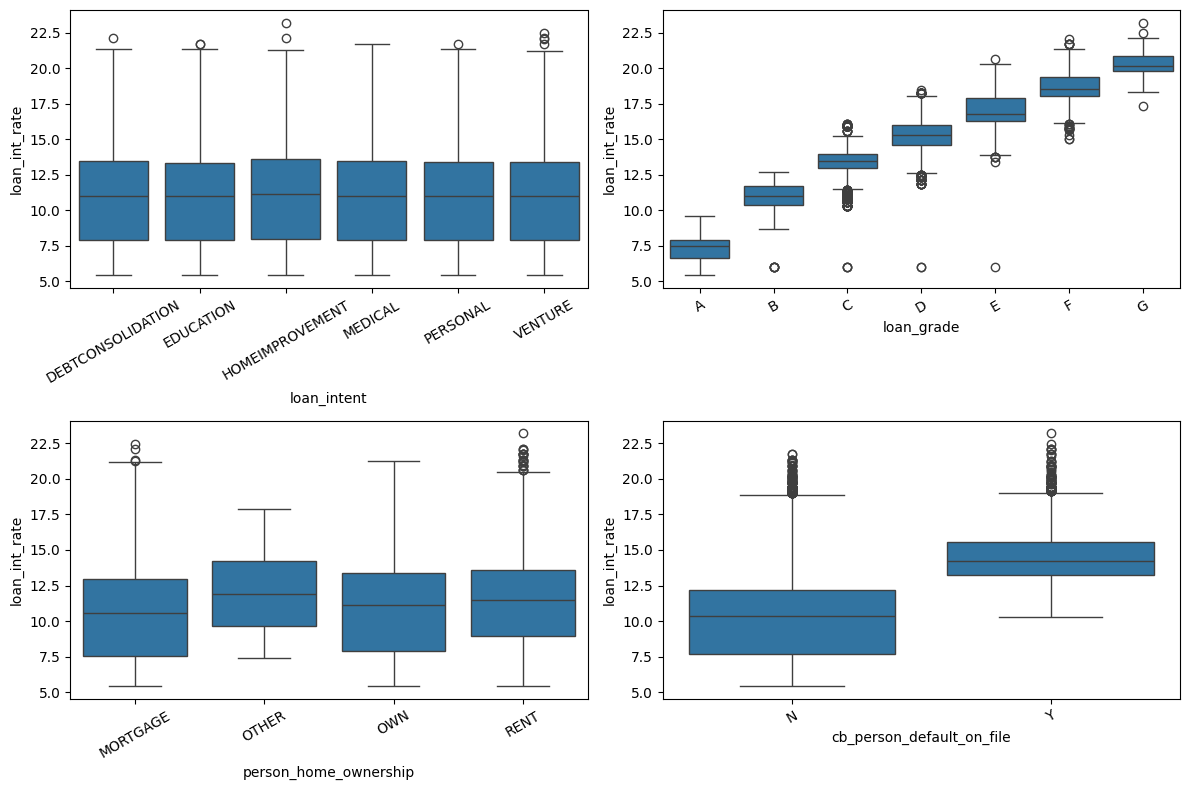

In [12]:
cats = ["loan_intent", "loan_grade", "person_home_ownership", "cb_person_default_on_file"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, cats):
    order = sorted(df_clean[col].dropna().unique())
    sns.boxplot(data=df_clean, x=col, y="loan_int_rate", order=order, ax=ax)
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

The interest rate rises steadily with loan grade and the boxes barely overlap, so grade alone would explain most of the variance. Since grade is assigned by the lender, likely from the same information I'm trying to model, including it would make the model circular. Also as expected default on file has a bigger gap between the boxplots, since defaulting on a loan in the past leads to higher risk for the bank. By contrast, home ownership and loan intent both have mostly overlapping boxes and look like weak predictors on their own. One strong feature and several weaker ones set expectations for the models that follow.

## Skewed Features

In [13]:
df_clean.select_dtypes("number").skew().sort_values(ascending=False).round(2)

person_income                 9.05
person_age                    1.92
cb_person_cred_hist_length    1.66
loan_status                   1.38
person_emp_length             1.25
loan_amnt                     1.17
loan_percent_income           1.08
loan_int_rate                 0.20
dtype: float64

With `person income` being skewed heavily to the right (skew 9.05), it will be log-transformed in the feature pipeline. I will do the same for `loan amount` (mildly skewed 1.17), since money amounts conventionally get logged and the transformation is harmless. The remaining features are mildly right-skewed from their zero bound and left as they are.

## Conclusion

The data set consists of simulated credit data in the style of US consumer lending, so the findings describe the simulation rather than real borrowers. Data cleaning removed 3,949 rows (about 12%), mostly due to missing interest rates, with the remainder dropped for implausible or missing age and employment-length values. I kept the rows with employment ages starting at 14, since model performance is not affected by them (notebook 02). Since loan grade almost fully decides the interest rate and possibly is assigned from the same information as well, I will exclude it from my model. I will log-transform `person_income` and `loan_amount` in the feature pipeline. Overall the EDA suggests that the observable features carry low signal and limited information on the interest rate, with one clearer signal (default on file) and multiple weaker ones.